In [ ]:
!pip -q install datasets opencv-python-headless pandas matplotlib

In [ ]:
from datasets import load_dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cv2
from collections import Counter

dataset = load_dataset("Francesco/road-traffic")

print(dataset)
print("\nAvailable splits:", list(dataset.keys()))

DatasetDict({
    train: Dataset({
        features: ['image_id', 'image', 'width', 'height', 'objects'],
        num_rows: 494
    })
    validation: Dataset({
        features: ['image_id', 'image', 'width', 'height', 'objects'],
        num_rows: 133
    })
    test: Dataset({
        features: ['image_id', 'image', 'width', 'height', 'objects'],
        num_rows: 187
    })
})

Available splits: ['train', 'validation', 'test']


In [ ]:
split_name = "train" if "train" in dataset else list(dataset.keys())[0]
data = dataset[split_name]

print("Selected split:", split_name)
print("Number of images:", len(data))
print("\nDataset features:")
print(data.features)

print("\nFirst sample fields:")
print(data[0].keys())

print("\nFirst sample annotations:")
print(data[0]["objects"])

Selected split: train
Number of images: 494

Dataset features:
{'image_id': Value('int64'), 'image': Image(mode=None, decode=True), 'width': Value('int32'), 'height': Value('int32'), 'objects': {'id': List(Value('int64')), 'area': List(Value('int64')), 'bbox': List(List(Value('float32'), length=4)), 'category': List(ClassLabel(names=['road-traffic', 'bicycles', 'buses', 'crosswalks', 'fire hydrants', 'motorcycles', 'traffic lights', 'vehicles']))}}

First sample fields:
dict_keys(['image_id', 'image', 'width', 'height', 'objects'])

First sample annotations:
{'id': [1714, 1715, 1716], 'area': [3024, 7224, 19530], 'bbox': [[280.0, 150.0, 63.0, 48.0], [2.0, 205.0, 129.0, 56.0], [9.0, 236.0, 630.0, 31.0]], 'category': [7, 3, 3]}


Category information: List(ClassLabel(names=['road-traffic', 'bicycles', 'buses', 'crosswalks', 'fire hydrants', 'motorcycles', 'traffic lights', 'vehicles']))


,Class,Object Count
0,vehicles,763
5,traffic lights,459
2,motorcycles,158
1,crosswalks,157
4,buses,88
3,fire hydrants,60
6,bicycles,46


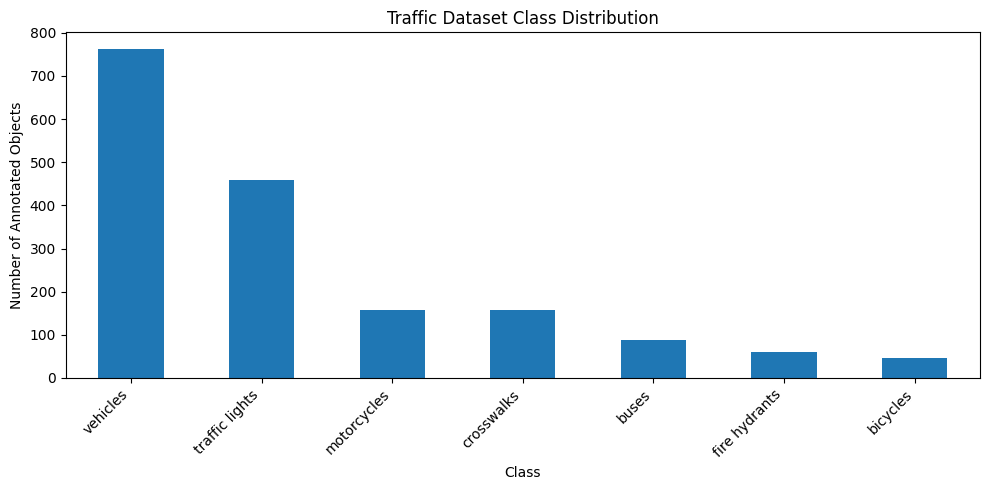

In [ ]:
category_feature = data.features["objects"]["category"]
print("Category information:", category_feature)

category_names = (
    category_feature.feature.names
    if hasattr(category_feature, "feature")
    and hasattr(category_feature.feature, "names")
    else None
)

counts = Counter()

for sample in data:
    for category in sample["objects"]["category"]:
        if category_names:
            name = category_names[int(category)]
        else:
            name = str(category)
        counts[name] += 1

class_df = pd.DataFrame(
    counts.items(), columns=["Class", "Object Count"]
).sort_values("Object Count", ascending=False)

display(class_df)

class_df.plot(
    x="Class", y="Object Count",
    kind="bar", legend=False, figsize=(10, 5)
)
plt.title("Traffic Dataset Class Distribution")
plt.ylabel("Number of Annotated Objects")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

,Image ID,Width,Height,Brightness,Blur Score
0,486,640,640,124.83,230.75
1,457,640,640,115.12,14.05
2,297,640,640,79.49,7.34
3,303,640,640,127.73,64.12
4,168,640,640,145.55,78.49
5,438,640,640,102.88,29.80
6,176,640,640,99.21,45.96
7,288,640,640,123.83,178.48
8,325,640,640,99.75,16.30
9,316,640,640,114.64,304.76


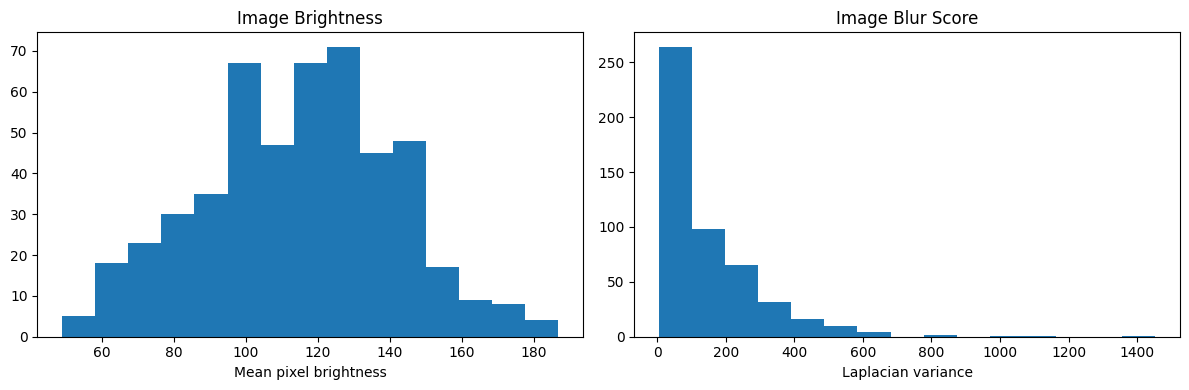

In [ ]:
quality = []

for i, sample in enumerate(data):
    image = sample["image"].convert("RGB")
    arr = np.array(image)
    gray = cv2.cvtColor(arr, cv2.COLOR_RGB2GRAY)

    quality.append({
        "Image ID": sample.get("image_id", i),
        "Width": image.width,
        "Height": image.height,
        "Brightness": round(float(gray.mean()), 2),
        "Blur Score": round(
            float(cv2.Laplacian(gray, cv2.CV_64F).var()), 2
        )
    })

quality_df = pd.DataFrame(quality)
display(quality_df.head(10))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(quality_df["Brightness"], bins=15)
axes[0].set_title("Image Brightness")
axes[0].set_xlabel("Mean pixel brightness")

axes[1].hist(quality_df["Blur Score"], bins=15)
axes[1].set_title("Image Blur Score")
axes[1].set_xlabel("Laplacian variance")

plt.tight_layout()
plt.show()

In [ ]:
valid = 0
invalid = 0
issues = []

for i, sample in enumerate(data):
    width, height = sample["image"].size
    objects = sample["objects"]

    for j, bbox in enumerate(objects["bbox"]):
        x, y, w, h = map(float, bbox)

        if (
            not np.all(np.isfinite([x, y, w, h]))
            or w <= 0 or h <= 0
            or x < 0 or y < 0
            or x + w > width or y + h > height
        ):
            invalid += 1
            issues.append({
                "Image Index": i,
                "Annotation Index": j,
                "Bounding Box": bbox,
                "Issue": "Invalid or out-of-bounds box"
            })
        else:
            valid += 1

print("Valid bounding boxes:", valid)
print("Invalid bounding boxes:", invalid)

issues_df = pd.DataFrame(issues)
display(issues_df.head(20))

Valid bounding boxes: 1731
Invalid bounding boxes: 0


""


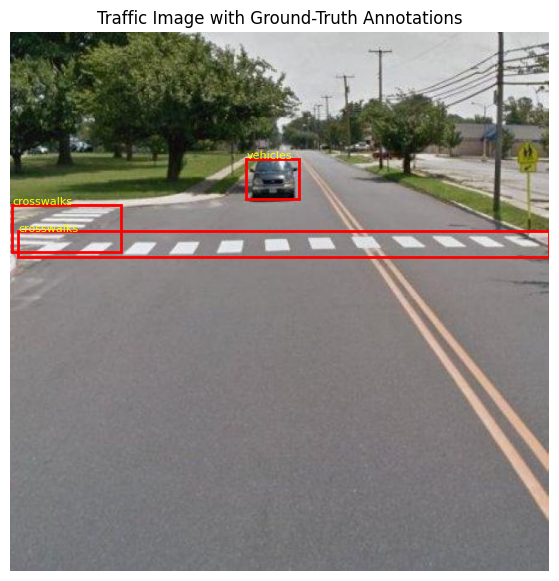

In [ ]:
sample = data[0]
image = sample["image"].convert("RGB")

fig, ax = plt.subplots(figsize=(12, 7))
ax.imshow(image)

for bbox, category in zip(
    sample["objects"]["bbox"],
    sample["objects"]["category"]
):
    x, y, w, h = bbox

    name = (
        category_names[int(category)]
        if category_names else str(category)
    )

    rect = plt.Rectangle(
        (x, y), w, h,
        fill=False, edgecolor="red", linewidth=2
    )
    ax.add_patch(rect)
    ax.text(x, y, name, color="yellow", fontsize=8)

ax.set_title("Traffic Image with Ground-Truth Annotations")
ax.axis("off")
plt.show()

In [ ]:
class_df.to_csv("/content/class_distribution.csv", index=False)
quality_df.to_csv("/content/image_quality.csv", index=False)
issues_df.to_csv("/content/annotation_issues.csv", index=False)

print("Dataset audit completed!")
print("Images analysed:", len(quality_df))
print("Valid boxes:", valid)
print("Invalid boxes:", invalid)

Dataset audit completed!
Images analysed: 494
Valid boxes: 1731
Invalid boxes: 0


In [ ]:
from google.colab import files
from PIL import Image
import io

uploaded = files.upload()

print("Number of uploaded images:", len(uploaded))
print("Uploaded files:", list(uploaded.keys()))

Saving Clear vs Blurry Traffic Scenes.png to Clear vs Blurry Traffic Scenes.png
Number of uploaded images: 1
Uploaded files: ['Clear vs Blurry Traffic Scenes.png']


In [ ]:
user_results = []
user_images = []

for filename, file_bytes in uploaded.items():
    try:
        image = Image.open(io.BytesIO(file_bytes)).convert("RGB")
        arr = np.array(image)

        gray = cv2.cvtColor(arr, cv2.COLOR_RGB2GRAY)

        blur_score = float(
            cv2.Laplacian(gray, cv2.CV_64F).var()
        )
        brightness = float(gray.mean())

        # Initial threshold; adjust after testing your images
        status = "Blurry" if blur_score < 100 else "Clear"

        user_results.append({
            "Image": filename,
            "Width": image.width,
            "Height": image.height,
            "Brightness": round(brightness, 2),
            "Blur Score": round(blur_score, 2),
            "Estimated Quality": status
        })

        user_images.append((filename, arr, blur_score, status))

    except Exception as e:
        print(f"Could not process {filename}: {e}")

user_quality_df = pd.DataFrame(user_results)
display(user_quality_df)

,Image,Width,Height,Brightness,Blur Score,Estimated Quality
0,Clear vs Blurry Traffic Scenes.png,1536,1024,140.5,489.6,Clear


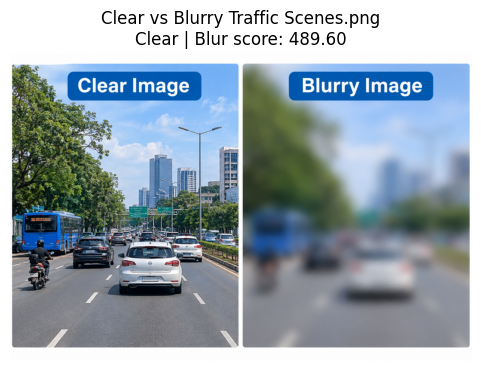

In [ ]:
for filename, arr, score, status in user_images:
    plt.figure(figsize=(6, 4))
    plt.imshow(arr)
    plt.title(f"{filename}\n{status} | Blur score: {score:.2f}")
    plt.axis("off")
    plt.show()

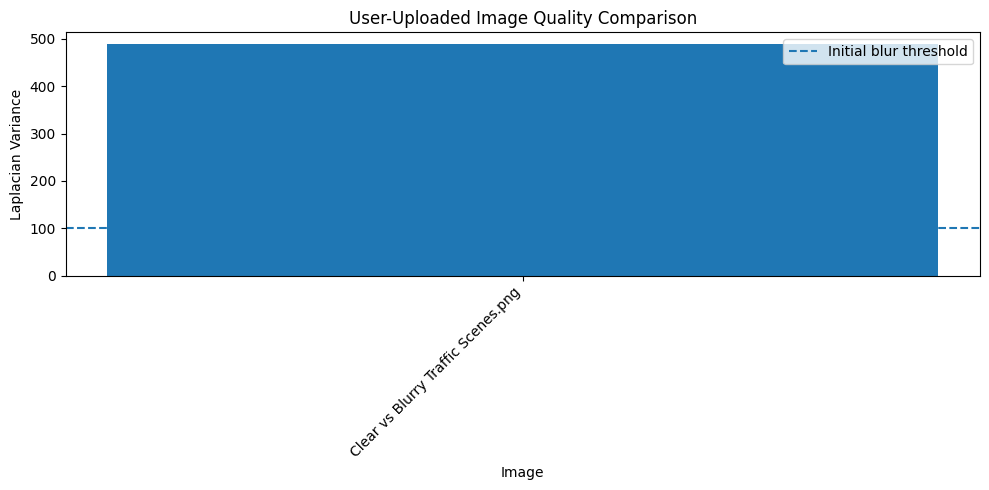

In [ ]:
if not user_quality_df.empty:
    plt.figure(figsize=(10, 5))

    plt.bar(
        user_quality_df["Image"],
        user_quality_df["Blur Score"]
    )

    plt.axhline(
        100, linestyle="--",
        label="Initial blur threshold"
    )

    plt.title("User-Uploaded Image Quality Comparison")
    plt.xlabel("Image")
    plt.ylabel("Laplacian Variance")
    plt.xticks(rotation=45, ha="right")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [ ]:
user_quality_df.to_csv(
    "/content/user_image_quality_results.csv",
    index=False
)

print("User image analysis completed!")
print("Images analysed:", len(user_quality_df))
print("\nQuality summary:")
print(user_quality_df["Estimated Quality"].value_counts())

User image analysis completed!
Images analysed: 1

Quality summary:
Estimated Quality
Clear    1
Name: count, dtype: int64
